# ClearPath: results overview

Quick view of **every result of the POC** in one place. Run all cells (*Run All*), which takes about 10 seconds.

- **Sections 1-4** read the evidence files in `document/other/evidence/` (written by `train_model.py`, `evaluate_vision.py` and `pytest`). Nothing is retrained here.
- **Section 5** runs the **real pipeline live** (governance → NLP → vision → grouping → letter → IoT → escalation → erasure) on a **temporary** database, so the demo data used by the app is never touched.

For the step-by-step explanation of the NLP and vision techniques, see `nlp_vision_analysis.ipynb`.

**Data:** the training texts and the sidewalk images are **synthetic**; the NLP blind test has 60 sentences written separately from the generator templates (never used in training).

In [1]:
import os, sys, json, re, pathlib, tempfile
# Temporary runtime folder BEFORE importing clearpath: the live demo never touches src/data/runtime
os.environ['CLEARPATH_RUNTIME'] = tempfile.mkdtemp(prefix='clearpath_notebook_')
# repository root = first folder (cwd or above) with pyproject.toml; works whatever the kernel's working dir is
REPO = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / 'pyproject.toml').exists())
SRC = REPO / 'src'                     # source code and data
EVIDENCE = REPO / 'document' / 'other' / 'evidence'
CHARTS = REPO / 'assets' / 'charts'
sys.path.insert(0, str(SRC / 'backend'))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.max_colwidth', 120)
nlp_m = json.loads((EVIDENCE / 'nlp_metrics.json').read_text(encoding='utf-8'))
vis_m = json.loads((EVIDENCE / 'vision_metrics.json').read_text(encoding='utf-8'))
tests_txt = (EVIDENCE / 'test_results.txt').read_text(encoding='utf-8')

## 1. Summary

In [2]:
chosen = next(m for m in nlp_m['comparison'] if m['model'] == nlp_m['chosen_model'])
passed = int(re.search(r'(\d+) passed', tests_txt).group(1))
failed = int(m.group(1)) if (m := re.search(r'(\d+) failed', tests_txt)) else 0
summary = pd.DataFrame([
    ['NLP classifier', 'macro F1 (blind test)', f"{chosen['f1_blind_test']:.3f}", '60 hand-written sentences'],
    ['NLP classifier', 'accuracy (blind test)', f"{chosen['accuracy_blind_test']:.1%}", nlp_m['chosen_model']],
    ['NLP classifier', 'macro F1 (5-fold CV)', f"{chosen['f1_cv']:.3f}", '1,320 synthetic reports'],
    ['Computer vision', 'accuracy (3 levels)', f"{vis_m['test_accuracy']:.1%}", f"{vis_m['n_images']} synthetic test images"],
    ['Automated tests', 'pytest', f'{passed} passed / {failed} failed', 'test_results.txt'],
], columns=['component', 'metric', 'result', 'basis'])
summary

,component,metric,result,basis
0,NLP classifier,macro F1 (blind test),0.899,60 hand-written sentences
1,NLP classifier,accuracy (blind test),90.0%,Logistic Regression (words + characters)
2,NLP classifier,macro F1 (5-fold CV),1.000,"1,320 synthetic reports"
3,Computer vision,accuracy (3 levels),86.7%,45 synthetic test images
4,Automated tests,pytest,39 passed / 0 failed,test_results.txt


## 2. NLP: report classifier
### Model comparison

In [3]:
pd.read_csv(EVIDENCE / 'nlp_model_comparison.csv')

,model,f1_cv,f1_cv_std,f1_blind_test,accuracy_blind_test
0,Naive Bayes (words),0.9977,0.0045,0.8991,0.9000
1,Logistic Regression (words + characters),1.0000,0.0000,0.8987,0.9000
2,Calibrated linear SVM (words + characters),1.0000,0.0000,0.8814,0.8833


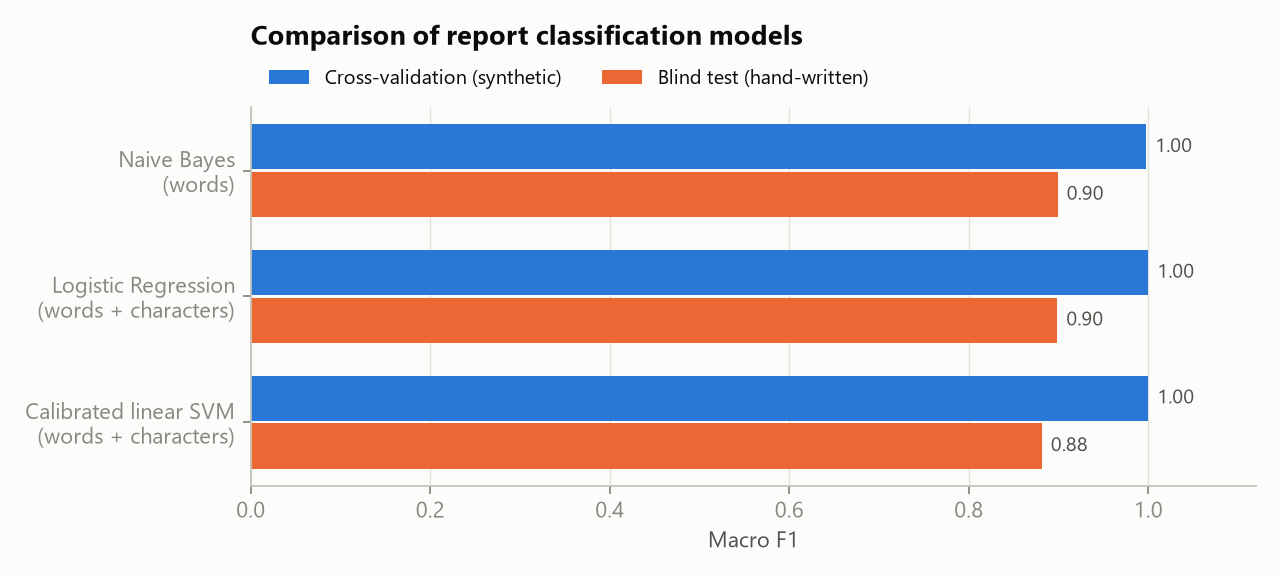

In [4]:
display(Image(CHARTS / 'nlp_model_comparison.png', width=700))

### Per-category result on the blind test

In [5]:
rep = pd.DataFrame(nlp_m['blind_test_report']).T
rep[['precision', 'recall', 'f1-score']] = rep[['precision', 'recall', 'f1-score']].round(3)
rep['support'] = rep['support'].astype(int)
rep

,precision,recall,f1-score,support
accessible_transit,0.833,1.0,0.909,10
crossing_signal,0.900,0.9,0.900,10
damaged_sidewalk,0.900,0.9,0.900,10
ramp_access,0.909,1.0,0.952,10
sidewalk_obstruction,1.000,0.8,0.889,10
tactile_paving,0.889,0.8,0.842,10
accuracy,0.900,0.9,0.900,0
macro avg,0.905,0.9,0.899,60
weighted avg,0.905,0.9,0.899,60


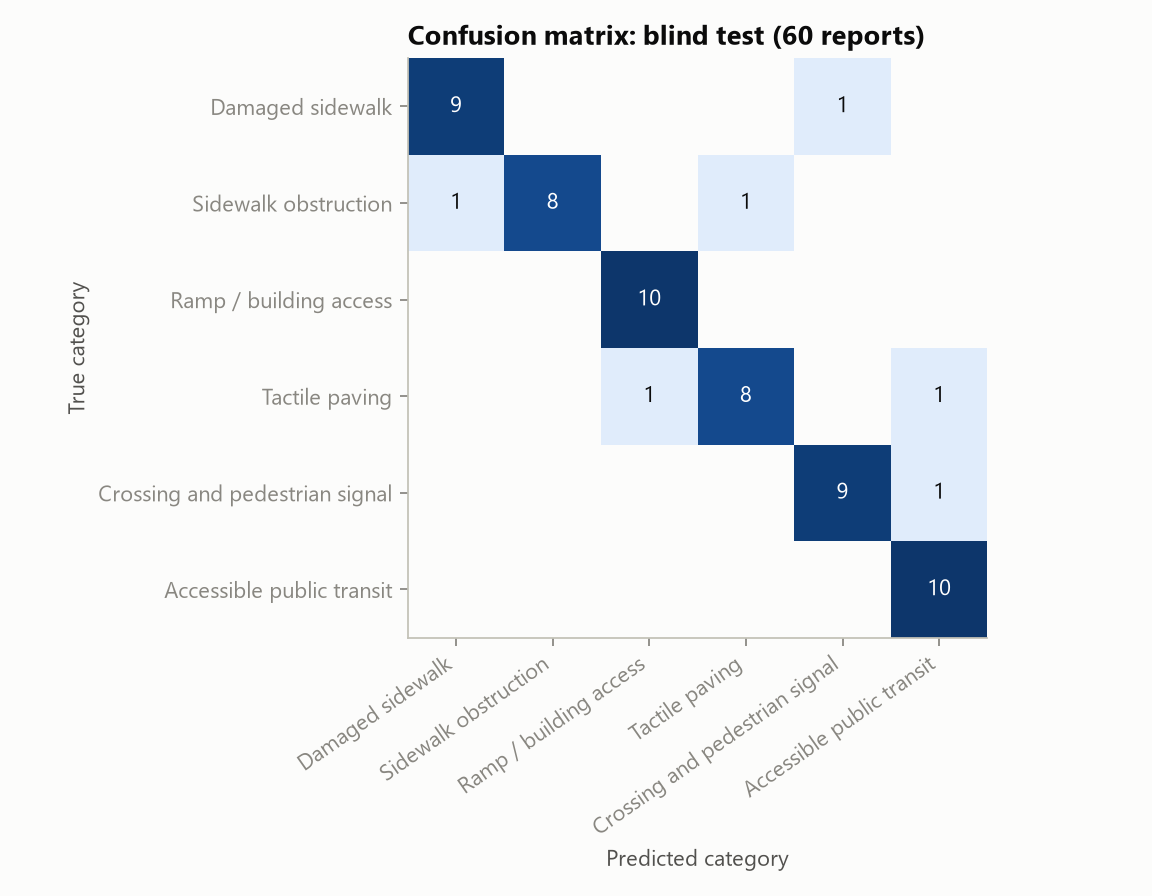

In [6]:
display(Image(CHARTS / 'nlp_confusion_matrix.png', width=600))

### Where it fails (blind-test errors)

In [7]:
pd.read_csv(EVIDENCE / 'nlp_blind_test_errors.csv')[['text', 'category', 'predicted']]

,text,category,predicted
0,I tripped on a raised concrete slab near the corner store,damaged_sidewalk,crossing_signal
1,there is a pile of sand and bricks from a renovation covering the path,sidewalk_obstruction,tactile_paving
2,Street vendors occupy the entire sidewalk at the terminal exit,sidewalk_obstruction,damaged_sidewalk
3,There is no floor signage for cane users in the square,tactile_paving,accessible_transit
4,Pieces of the directional tiles are missing on the terminal ramp,tactile_paving,ramp_access
5,"The zebra stripes are gone from wear, drivers don't even stop",crossing_signal,accessible_transit


## 3. Computer vision: sidewalk damage

In [8]:
labels = vis_m['confusion_matrix']['labels']
print(f"accuracy: {vis_m['test_accuracy']:.1%} | thresholds: {vis_m['thresholds']}")
pd.DataFrame(vis_m['confusion_matrix']['values'], index=['true: ' + l for l in labels], columns=['pred: ' + l for l in labels])

accuracy: 86.7% | thresholds: {'moderate': 6, 'severe': 27}


,pred: no visible damage,pred: moderate,pred: severe
true: no visible damage,13,2,0
true: moderate,3,12,0
true: severe,0,1,14


In [9]:
vis = pd.read_csv(EVIDENCE / 'vision_test_results.csv')
print('Misclassified images:')
vis[vis.true_level != vis.level][['file', 'true_level', 'level', 'damage_index', 'crack_pct', 'pothole_pct']]

Misclassified images:


,file,true_level,level,damage_index,crack_pct,pothole_pct
0,no_visible_damage_00.jpg,no visible damage,moderate,9.1,1.01,0.00
11,no_visible_damage_11.jpg,no visible damage,moderate,13.4,0.86,0.95
17,moderate_02.jpg,moderate,no visible damage,5.4,0.60,0.00
21,moderate_06.jpg,moderate,no visible damage,5.5,0.61,0.00
22,moderate_07.jpg,moderate,no visible damage,5.9,0.65,0.00
35,severe_05.jpg,severe,moderate,24.9,1.76,1.52


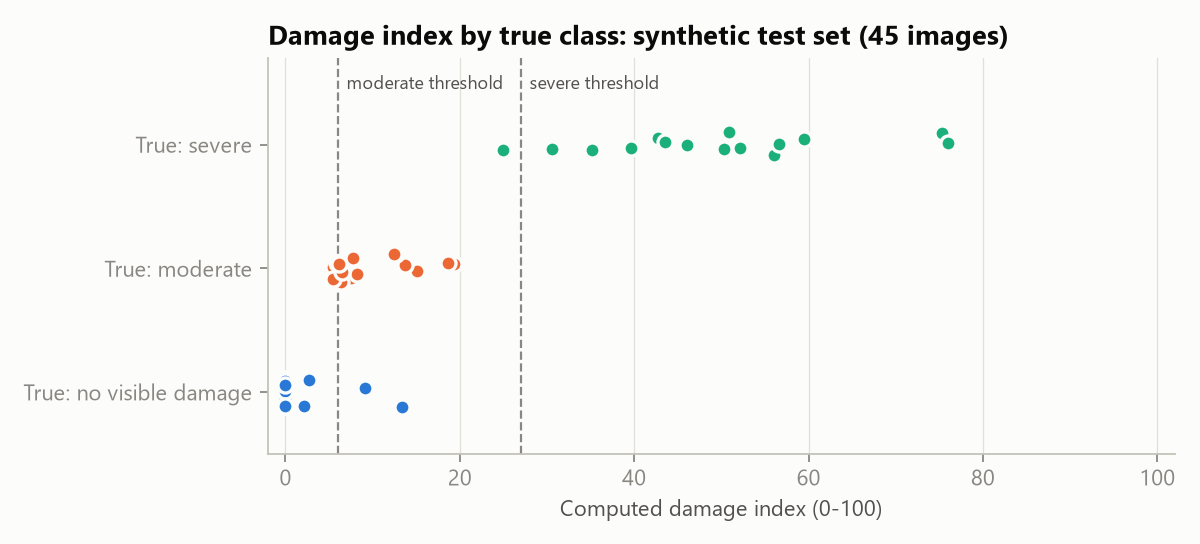

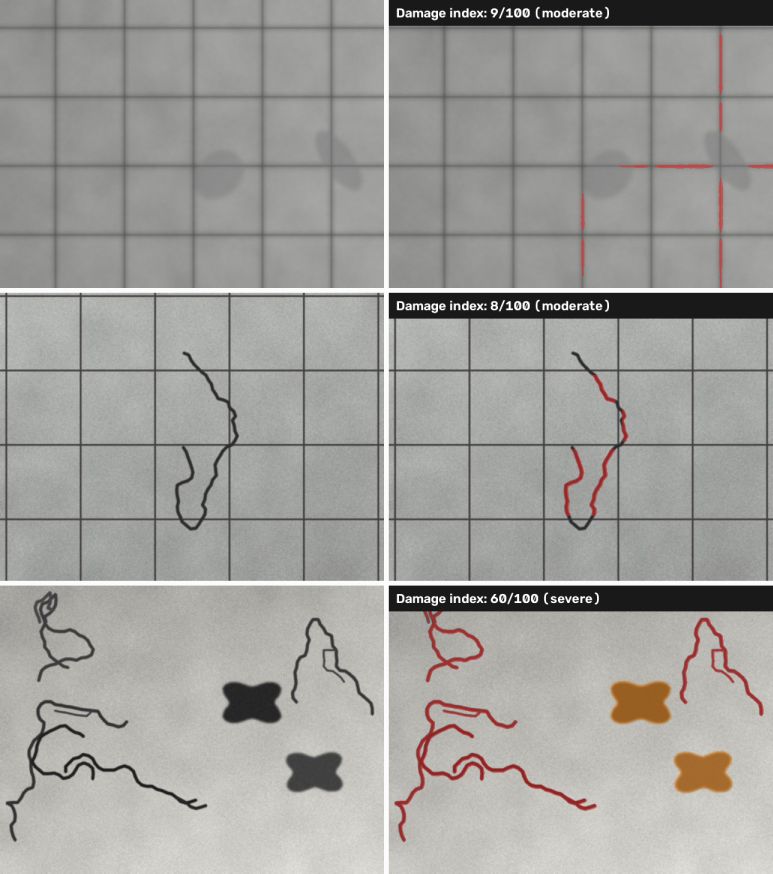

In [10]:
display(Image(CHARTS / 'vision_index_by_class.png', width=650))
display(Image(CHARTS / 'vision_examples.png', width=900))

## 4. Automated tests

In [11]:
results = re.findall(r'^tests/(\w+)\.py::.* (PASSED|FAILED|ERROR)', tests_txt, re.M)
pd.DataFrame(results, columns=['file', 'result']).value_counts().unstack(fill_value=0)

result
file


## 5. Live demo of the pipeline
Everything below calls the real `clearpath` package on a temporary database.

In [12]:
from clearpath import db, service, routing, iot, config
import email, email.policy
con = db.connect()
print('temporary database:', config.DB_FILE)

def show(r):
    keys = ['protocol', 'category_label', 'confidence', 'human_review', 'address', 'priority', 'urgency_points',
            'urgency_reasons', 'damage_level', 'damage_index', 'group_root', 'agency', 'deadline', 'status']
    return pd.Series({k: r.get(k) for k in keys}, name=r['protocol']).to_frame()

temporary database: C:\Users\Vinicius\AppData\Local\Temp\clearpath_notebook_9vki7696\clearpath.sqlite3


### 5.1 A citizen report with personal data and a photo
The CPF and the phone are masked **before** anything is stored; the photo is re-encoded without EXIF and analyzed.

In [13]:
text = ('Urgent! The sidewalk on Rua Augusta, 1500 is completely broken with a huge hole, '
        'my elderly mother fell yesterday. My cpf is 123.456.789-09, call me at (11) 98765-4321')
photo = (SRC / 'data' / 'demo_images' / 'test' / 'severe_03.jpg').read_bytes()
r1 = service.process_report(con, text, lat=-23.554512, lon=-46.627533, photo=photo)
print('personal data removed:', r1['personal_data_removed'])
print('stored text          :', r1['anonymized_text'])
print('stored coordinates   :', r1['lat'], r1['lon'])
show(r1)

personal data removed: {'CPF': 1, 'PHONE': 1}
stored text          : Urgent! The sidewalk on Rua Augusta, 1500 is completely broken with a huge hole, my elderly mother fell yesterday. My cpf is [CPF], call me at [PHONE]
stored coordinates   : -23.5545 -46.6275


,CP-2026-000001
protocol,CP-2026-000001
category_label,Damaged sidewalk
confidence,0.992
human_review,False
address,"Rua Augusta, 1500"
priority,critical
urgency_points,92
urgency_reasons,fall or accident reported; vulnerable person affected; risk declared; photo shows severe damage
damage_level,severe
damage_index,42.7


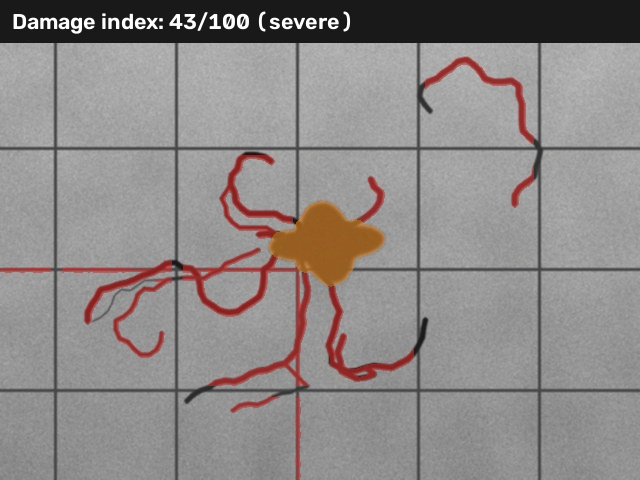

In [14]:
display(Image(config.MEDIA_DIR / r1['photo_analysis'], width=450))

### 5.2 The letter generated for the responsible agency (`.eml`, not sent)

In [15]:
letter = sorted(config.LETTERS_DIR.glob(f"{r1['protocol']}*.eml"))[0]
msg = email.message_from_bytes(letter.read_bytes(), policy=email.policy.default)
print('To:', msg['To']); print('Subject:', msg['Subject']); print()
print(msg.get_body(preferencelist=('plain',)).get_content())

To: sidewalk.maintenance@subprefecture.invalid
Subject: [FORWARDING] ClearPath CP-2026-000001 - critical

To: Subprefecture (sidewalk maintenance),

ClearPath received a report about an accessibility barrier and forwards it for action.

Protocol: CP-2026-000001
Category: Damaged sidewalk
Priority: CRITICAL (score 92)
Reasons: fall or accident reported; vulnerable person affected; risk declared; photo shows severe damage
Address mentioned: Rua Augusta, 1500
Coordinates: -23.5545, -46.6275 https://www.openstreetmap.org/?mlat=-23.5545&mlon=-46.6275#map=19/-23.5545/-46.6275
Photo assessment: severe
Response deadline (SLA): 2026-11-22
Legal basis: São Paulo Municipal Law 15,442/2011 (sidewalks) and ABNT NBR 9050:2020 (Brazilian accessibility standard), item 6.12

Citizen's report (anonymized):
"Urgent! The sidewalk on Rua Augusta, 1500 is completely broken with a huge hole, my elderly mother fell yesterday. My cpf is [CPF], call me at [PHONE]"

Update the progress at PATCH /api/reports/CP-2

### 5.3 A second citizen reports the same barrier (≤ 60 m away)
The new report is grouped with the first one and the original occurrence gains priority.

In [16]:
r2 = service.process_report(con, 'There is a big hole in the sidewalk here, I use a wheelchair and cannot get through',
                            lat=-23.554600, lon=-46.627400)
print('grouped with:', r2['group_root'])
pd.DataFrame(service.get_report(con, r1['protocol'])['history'])

grouped with: CP-2026-000001


,at,status,note
0,2026-11-20T00:04:51-03:00,received,Report received through the citizen app
1,2026-11-20T00:04:51-03:00,forwarded,Automatic letter to Subprefecture (sidewalk maintenance)
2,2026-11-20T00:04:51-03:00,forwarded,New report about the same barrier (CP-2026-000002)


### 5.4 A vague report goes to human triage

In [17]:
r3 = service.process_report(con, 'something is wrong over there, please do something')
print(f"confidence {r3['confidence']:.2f} < threshold → status: {r3['status']}")

confidence 0.24 < threshold → status: human_triage


### 5.5 IoT: the Ramp Sentinel detects a car in front of a ramp
Same JSON the ESP32 publishes over MQTT (here passed directly, without the broker).

In [18]:
sensor = {'device': 'ramp-notebook-01', 'location': 'Ramp at Rua Vergueiro, 1000', 'lat': -23.5701, 'lon': -46.6395}
for event in [{'event': 'heartbeat', 'distance_cm': 180},
              {'event': 'obstruction', 'distance_cm': 42, 'duration_s': 95},
              {'event': 'confirmation', 'distance_cm': 41}]:
    print(event['event'].ljust(12), '→', iot.process_message(con, {**sensor, **event}))

heartbeat    → {'action': 'heartbeat_recorded'}
obstruction  → {'action': 'report_created', 'protocol': 'CP-2026-000004', 'priority': 'medium'}
confirmation → {'action': 'report_reinforced', 'protocol': 'CP-2026-000004', 'priority': 'medium'}


### 5.6 SLA robot: 40 days later, overdue reports are escalated to the Ombudsman

In [19]:
from datetime import timedelta
escalated = routing.escalate_overdue(con, reference=db.now() + timedelta(days=40))
print('escalated:', escalated)

escalated: ['CP-2026-000001', 'CP-2026-000002', 'CP-2026-000004']


### 5.7 Right to erasure (LGPD art. 18, VI) and the audit log

In [20]:
service.erase_data(con, r1['protocol'])
after = service.get_report(con, r1['protocol'])
print('text :', after['anonymized_text']); print('photo:', after['photo'])
pd.DataFrame([dict(a) for a in con.execute('SELECT at, action, protocol, detail FROM audit_log ORDER BY id')])

text : [removed at the data subject's request]
photo: None


,at,action,protocol,detail
0,2026-11-20T00:04:51-03:00,report_collected,CP-2026-000001,"{""personal_data_removed"": {""CPF"": 1, ""PHONE"": 1}, ""photo_without_exif"": true}"
1,2026-11-20T00:04:51-03:00,report_collected,CP-2026-000002,"{""personal_data_removed"": {}, ""photo_without_exif"": false}"
2,2026-11-20T00:04:51-03:00,report_collected,CP-2026-000003,"{""personal_data_removed"": {}, ""photo_without_exif"": false}"
3,2026-11-20T00:04:51-03:00,report_collected,CP-2026-000004,"{""personal_data_removed"": {}, ""photo_without_exif"": false}"
4,2026-11-20T00:04:51-03:00,automatic_escalation,CP-2026-000001,SLA missed
5,2026-11-20T00:04:51-03:00,automatic_escalation,CP-2026-000002,SLA missed
6,2026-11-20T00:04:51-03:00,automatic_escalation,CP-2026-000004,SLA missed
7,2026-11-20T00:04:51-03:00,erasure_on_request,CP-2026-000001,photos and text removed


### 5.8 Try your own report
Change the text and run the cell again.

In [21]:
my_text = 'The traffic light at Av. Paulista has no sound signal, I am blind and cannot cross safely'
show(service.process_report(con, my_text))

,CP-2026-000005
protocol,CP-2026-000005
category_label,Crossing and pedestrian signal
confidence,0.991
human_review,False
address,Av. Paulista
priority,medium
urgency_points,50
urgency_reasons,person with disability affected
damage_level,None
damage_index,None
